# Reto AgroCebada FIRA 2026
## Libreta 03 · Validación Robusta y Ablación

> *"¿Cuánto del desempeño viene de la ubicación y cuánto de las variables agronómicas?"*

### Sección del Reporte que alimenta esta libreta
| Sección del Reporte | Contenido generado aquí |
|---|---|
| **Resultados y Discusión** | Validación (interpolación vs. zonas nuevas), comparativa de modelos, diferencias pareadas, ablación por bloques, prueba de residuos |

### El problema que resolvemos aquí
En agricultura de precisión es común evaluar modelos con validaciones que **no separan observaciones espacialmente cercanas**. Cuando parcelas vecinas comparten manejo, suelo y microclima, un algoritmo flexible puede *memorizar la ubicación* y reportar un error que no se sostiene al predecir en zonas nuevas. La Primera Ley de Tobler lo anticipa: las cosas cercanas están más relacionadas que las lejanas.

### Objetivos de esta libreta
1. Evaluar con tres esquemas: **RepeatedKFold** (parcelas intercaladas = interpolación), **GroupKFold por celdas CHIRPS** y **Leave-One-Group-Out por municipio** (zonas nuevas).
2. Comparar **cinco modelos en los MISMOS folds**: Dummy (media), KNN espacial (solo lat/lon), HGB agronómico (sin coordenadas), HGB final (coordenadas + variables, `SelectKBest`) y el **ensamble 50/50** KNN + HGB final.
3. Calcular **diferencias pareadas por fold** y aplicar la **regla de decisión fijada de antemano**.
4. **Ablación por bloques** de variables (quitar un bloque / usar solo un bloque) bajo RepeatedKFold y LOGO, con diferencias pareadas y su variabilidad.
5. **Prueba de residuos**: ¿los índices satelitales explican lo que el interpolador espacial no explica?

### Hipótesis (se contrastan; no se asume su resultado)
- **H1.** Si el HGB agronómico no supera al KNN espacial bajo validación espacial, su desempeño proviene sobre todo de la ubicación.
- **H2.** Si los índices satelitales explican los residuos del KNN (R² > 0 fuera de muestra), aportan información más allá de la ubicación.

### Cómo leer las métricas
- `MAE_pooled`, `RMSE_pooled`, `R2_pooled`: se calculan sobre las predicciones fuera de muestra de las 138 parcelas (en RepeatedKFold, una vez por repetición y luego se promedian las 3 repeticiones; **no** se promedian las predicciones entre repeticiones).
- `MAE_fold_media ± MAE_fold_sd`: media y desviación del MAE **por fold**. En LOGO cada fold es un municipio, así que la media es un promedio *por municipio* (macro), distinto del MAE pooled (que pondera por parcelas).
- **El ± es variabilidad entre folds, no un intervalo de confianza**, y los folds de RepeatedKFold no son independientes. Con 138 parcelas la prueba tiene poco poder para detectar diferencias pequeñas: "no detectada" no equivale a "inexistente".
- Los hiperparámetros se fijaron en el reporte usando estas mismas particiones, por lo que las cifras son ligeramente optimistas.

### Regla de decisión (definida ANTES de ver los resultados)
Se entrega el **ensamble** si su MAE medio por fold bajo RepeatedKFold no excede al del KNN en más de **0.02 t/ha** (`TOLERANCIA_DECISION`).

In [ ]:
# ============================================================
# CONFIGURACIÓN MAESTRA - Entorno
# ============================================================
import os
from pathlib import Path

EN_COLAB = True  # <-- Cambiar a False si el evaluador lo corre en su PC local (GitHub)

if EN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = Path('/content/drive/MyDrive/Reto_AgroCebada_2026')
else:
    # Usa el directorio actual (la raíz del repositorio clonado de GitHub)
    BASE = Path(os.getcwd())

CARPETAS = {
    'raw':           BASE / 'data' / 'raw',
    '01_calidad':    BASE / 'data' / '01_calidad',
    '02_fenologia':  BASE / 'data' / '02_fenologia',
    '03_validacion': BASE / 'data' / '03_validacion',
    '04_shap':       BASE / 'data' / '04_shap',
    '05_final':      BASE / 'data' / '05_final',
    'models':        BASE / 'models',
    'artifacts':     BASE / 'artifacts', # <-- Aquí irán los archivos del Dashboard
    'reports':       BASE / 'reports',
}

for carpeta in CARPETAS.values():
    carpeta.mkdir(parents=True, exist_ok=True)

def guardar_csv(df, nombre, carpeta='raw'):
    ruta = CARPETAS[carpeta] / nombre
    df.to_csv(ruta, index=False, encoding='utf-8-sig')
    print(f"✅ Guardado: {ruta}")
    return ruta

def cargar_csv(nombre, carpeta='raw', **kwargs):
    ruta = CARPETAS[carpeta] / nombre
    assert ruta.exists(), f"❌ No existe: {ruta}"
    df = pd.read_csv(ruta, **kwargs)
    print(f"📂 Cargado: {nombre} ({df.shape[0]} filas × {df.shape[1]} cols)")
    return df

def guardar_figura(fig, nombre, carpeta='reports'):
    ruta = CARPETAS[carpeta] / nombre
    fig.savefig(ruta, dpi=200, bbox_inches='tight')
    print(f"✅ Gráfico guardado: {ruta}")
    return ruta

def listar_archivos(carpeta='raw'):
    ruta = CARPETAS[carpeta]
    archivos = sorted(ruta.iterdir()) if ruta.exists() else []
    if not archivos:
        print(f"📁 Carpeta '{carpeta}' vacía")
    else:
        print(f"📁 Carpeta '{carpeta}': {len(archivos)} archivos")
        for a in archivos:
            tamaño = a.stat().st_size
            unidad = 'MB' if tamaño > 1e6 else 'KB' if tamaño > 1e3 else 'B'
            valor = tamaño / 1e6 if tamaño > 1e6 else tamaño / 1e3 if tamaño > 1e3 else tamaño
            print(f"   • {a.name} ({valor:.1f} {unidad})")
    return archivos

# Semillas y parámetros de validación
SEMILLA = 999
N_SPLITS_RK = 5
N_REPEATS_RK = 3
TAMANO_CELDA_CHIRPS = 0.05  # ~5 km, aproximación de la cuadrícula CHIRPS

# --- Constantes de la decisión y del modelo final (coinciden con el reporte) ---
TOLERANCIA_DECISION = 0.02          # t/ha; regla fijada antes del análisis final
SEMILLA_HGB_FINAL = 2026
K_VARS = 20                         # SelectKBest (información mutua) dentro de cada fold
FORZAR_COORDS_HGB_FINAL = True      # True: lat/lon entran siempre; False: compiten en SelectKBest

print("✅ Configuración Drive completada")
print(f"   Semilla global: {SEMILLA}")
print(f"   Tamaño de celda CHIRPS: {TAMANO_CELDA_CHIRPS}°")

Mounted at /content/drive
✅ Configuración Drive completada
   Semilla global: 999
   Tamaño de celda CHIRPS: 0.05°


In [ ]:
# Ruta explícita de la tabla maestra (rendimiento). Sustituye la búsqueda por nombre de archivo.
RUTA_MAESTRO = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026' / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
assert RUTA_MAESTRO.exists(), f"No existe: {RUTA_MAESTRO}"
print(f"✅ Tabla maestra: {RUTA_MAESTRO}")

✅ Tabla maestra: /content/drive/MyDrive/Reto_AgroCebada_2026/data/raw/extraido/DATASET_RETO_AGRO_2026/ID_area_rendimiento_70_30_Reto_AgroCebada.csv


In [ ]:
# ============================================================
# 1. CARGA DE DATOS DESDE DRIVE
# ============================================================
print("Cargando artefactos de la Libreta 02...")

# Matriz integrada de características (insumo principal)
X_integrado = cargar_csv('X_integrado_completo.csv', '02_fenologia')

# Variable objetivo (Cargada desde la ubicación encontrada real)
ruta_y_real = CARPETAS['raw'] / 'extraido' / 'DATASET_RETO_AGRO_2026' / 'ID_area_rendimiento_70_30_Reto_AgroCebada.csv'
if ruta_y_real.exists():
    y_df = pd.read_csv(ruta_y_real)
    print(f"📂 Cargado: y_rendimiento real desde {ruta_y_real.name} ({y_df.shape[0]} filas)")
else:
    # Fallback si no existiera en ejecución interactiva
    y_df = cargar_csv('y_rendimiento.csv', '01_calidad')

# Metadatos espaciales (coordenadas + municipio + estado) desde el shapefile
RAW = CARPETAS['raw'] / 'extraido'
shp_files = list(RAW.glob('**/*.shp'))
if not shp_files:
    shp_files = list((CARPETAS['raw'] / 'extraido').glob('*/*.shp'))
assert len(shp_files) >= 1, "No se encontró el shapefile de parcelas"
gdf_parcelas = gpd.read_file(shp_files[0])

# Normalizar columna ID
columnas_id = [c for c in gdf_parcelas.columns if 'ID_POL' in c.upper()]
if columnas_id:
    gdf_parcelas = gdf_parcelas.rename(columns={columnas_id[0]: 'ID_POLIGONO'})
gdf_parcelas['ID_POLIGONO'] = gdf_parcelas['ID_POLIGONO'].astype(str).str.strip()

# Extraer coordenadas de centroides (WGS84)
if gdf_parcelas.crs is None:
    gdf_parcelas = gdf_parcelas.set_crs('EPSG:4326')
gdf_wgs84 = gdf_parcelas.to_crs(epsg=4326)
gdf_parcelas['latitud'] = gdf_wgs84.geometry.centroid.y
gdf_parcelas['longitud'] = gdf_wgs84.geometry.centroid.x

# Detectar columnas de municipio/estado
col_municipio = None
col_estado = None
for c in gdf_parcelas.columns:
    if 'munici' in c.lower():
        col_municipio = c
    if 'estado' in c.lower():
        col_estado = c

print(f"\n   Columna de municipio detectada: {col_municipio}")
print(f"   Columna de estado detectada: {col_estado}")

# Construir tabla de metadatos espaciales
meta_cols = {'ID_POLIGONO': gdf_parcelas['ID_POLIGONO'],
             'latitud': gdf_parcelas['latitud'],
             'longitud': gdf_parcelas['longitud']}
if col_municipio:
    meta_cols['municipio'] = gdf_parcelas[col_municipio]
if col_estado:
    meta_cols['estado'] = gdf_parcelas[col_estado]
df_meta = pd.DataFrame(meta_cols)

print(f"\n✅ Metadatos espaciales: {len(df_meta)} parcelas")
print(f"✅ X_integrado: {X_integrado.shape[0]} parcelas × {X_integrado.shape[1]} variables")
print(f"✅ y: {len(y_df)} etiquetas")

Cargando artefactos de la Libreta 02...
📂 Cargado: X_integrado_completo.csv (197 filas × 188 cols)
📂 Cargado: y_rendimiento real desde ID_area_rendimiento_70_30_Reto_AgroCebada.csv (197 filas)

   Columna de municipio detectada: Municipio
   Columna de estado detectada: Estado

✅ Metadatos espaciales: 197 parcelas
✅ X_integrado: 197 parcelas × 188 variables
✅ y: 197 etiquetas


In [ ]:
# ============================================================
# 2. PREPARAR MATRIZ DE VALIDACIÓN (138 PARCELAS ETIQUETADAS)
# ============================================================
X_integrado['ID_POLIGONO'] = X_integrado['ID_POLIGONO'].astype(str).str.strip()
y_df['ID_POLIGONO'] = y_df['ID_POLIGONO'].astype(str).str.strip()
df_meta['ID_POLIGONO'] = df_meta['ID_POLIGONO'].astype(str).str.strip()

# IDs de las 59 parcelas a predecir (se usan en la Libreta 04)
ids_prediccion = y_df.loc[y_df['RENDIMIENTO_T_HA'].isna(), 'ID_POLIGONO'].tolist()
assert len(ids_prediccion) == 59, f"Se esperaban 59 parcelas sin rendimiento; hay {len(ids_prediccion)}"
df_prediccion = (X_integrado[X_integrado['ID_POLIGONO'].isin(ids_prediccion)]
                 .merge(df_meta, on='ID_POLIGONO', how='left', validate='one_to_one')
                 .reset_index(drop=True))

# CORRECCIÓN: la tabla maestra también trae AREA_HA y CONJUNTO, y X_integrado ya trae AREA_HA.
# Unirlas completas creaba AREA_HA_x / AREA_HA_y y dejaba "Área: 0 variable". Solo se toma el rendimiento.
y_df = y_df[['ID_POLIGONO', 'RENDIMIENTO_T_HA']].copy()

df_trabajo = y_df.merge(X_integrado, on='ID_POLIGONO', how='inner', validate='one_to_one')
df_trabajo = df_trabajo.merge(df_meta, on='ID_POLIGONO', how='left', validate='one_to_one')
assert 'AREA_HA' in df_trabajo.columns, "AREA_HA no llegó a la matriz de trabajo"
df_trabajo = df_trabajo.dropna(subset=['RENDIMIENTO_T_HA']).reset_index(drop=True)
assert len(df_trabajo) == 138, f"Se esperaban 138 parcelas etiquetadas; hay {len(df_trabajo)}"

print(f"Parcelas con rendimiento conocido: {len(df_trabajo)}")
print(f"Rendimiento: media={df_trabajo['RENDIMIENTO_T_HA'].mean():.2f} t/ha, "
      f"std={df_trabajo['RENDIMIENTO_T_HA'].std():.2f} t/ha")

y = df_trabajo['RENDIMIENTO_T_HA'].reset_index(drop=True)
ids = df_trabajo['ID_POLIGONO'].reset_index(drop=True)
coords = df_trabajo[['latitud', 'longitud']].reset_index(drop=True)

# Variables candidatas: todas las numéricas que no son metadatos
COLS_META = ['ID_POLIGONO', 'RENDIMIENTO_T_HA', 'latitud', 'longitud', 'municipio', 'estado']
candidatas = [c for c in df_trabajo.columns if c not in COLS_META]
no_numericas = [c for c in candidatas if not pd.api.types.is_numeric_dtype(df_trabajo[c])]
if no_numericas:
    print(f"⚠️ Columnas no numéricas excluidas: {no_numericas}")
columnas_x = [c for c in candidatas if c not in no_numericas]

# Bloques de variables (por prefijo)
bloques = {
    'suelo_termico': [c for c in columnas_x if c.startswith('suelo_termico')],
    'vegetacion':    [c for c in columnas_x if c.startswith('vegetacion')],
    'fenologia':     [c for c in columnas_x if c.startswith('fenologia')],
    'agua':          [c for c in columnas_x if c.startswith('agua')],
    'topografia':    [c for c in columnas_x if c.startswith(('Elevacion', 'Pendiente'))],
    'clima':         [c for c in columnas_x if c.startswith(('PREC_', 'Tmin_', 'Tmax_'))],
    'fisica':        [c for c in columnas_x if c.startswith('fisica__')],
    'area':          [c for c in columnas_x if c == 'AREA_HA'],
}
sin_bloque = [c for c in columnas_x if not any(c in v for v in bloques.values())]

print("\n📊 Bloques de variables:")
for nombre, cols in bloques.items():
    print(f"   {nombre:14s}: {len(cols):3d} variables")
print(f"   {'TOTAL':14s}: {len(columnas_x):3d} variables")
if sin_bloque:
    print(f"⚠️ Variables sin bloque asignado: {sin_bloque}")

# Aserciones que habrían detectado los dos errores de la versión anterior
assert len(bloques['clima']) == 21, (
    f"El bloque de clima debe tener 21 variables y tiene {len(bloques['clima'])}. "
    "Ejecuta la Libreta 02 corregida (el filtro de meses usaba guion en lugar de guion bajo).")
assert len(bloques['area']) == 1, "AREA_HA debe estar exactamente una vez en la matriz."
assert len(columnas_x) == len(set(columnas_x)), "Hay columnas duplicadas en la matriz."

X_full = df_trabajo[columnas_x].reset_index(drop=True)
X_full_clean = X_full                                  # compatibilidad con nombres anteriores
cols_feat_hgb_final = list(X_full.columns)
X_hgb_final = pd.concat([X_full, coords], axis=1)      # variables + coordenadas

Parcelas con rendimiento conocido: 138
Rendimiento: media=3.96 t/ha, std=0.85 t/ha

📊 Bloques de variables:
   suelo_termico :   7 variables
   vegetacion    :   9 variables
   fenologia     : 135 variables
   agua          :   3 variables
   topografia    :   2 variables
   clima         :  21 variables
   fisica        :   9 variables
   area          :   1 variables
   TOTAL         : 187 variables


### 🗺️ Asignación de Grupos Espaciales

Para probar que el modelo **no memoriza geografía**, definimos dos esquemas de agrupamiento espacial:

1. **Celdas climáticas CHIRPS**: aproximamos la cuadrícula de precipitación CHIRPS (~0.05° ≈ 5 km) redondeando las coordenadas de cada parcela. Dos parcelas en la misma celda comparten régimen de precipitación.

2. **Municipios**: agrupamiento administrativo. Las parcelas del mismo municipio comparten manejo, suelo, microclima y prácticas agronómicas.

**Regla de validación espacial estricta:** en cada fold, las parcelas del conjunto de validación pertenecen a grupos (celdas o municipios) que **no aparecen en absoluto** en el conjunto de entrenamiento. Esto elimina la fuga espacial.

In [ ]:
# ============================================================
# 3. ASIGNACIÓN DE GRUPOS ESPACIALES
# ============================================================

# --- Celdas CHIRPS (grid de ~0.05°) ---
lat_grid = np.floor(df_trabajo['latitud'].values / TAMANO_CELDA_CHIRPS).astype(int)
lon_grid = np.floor(df_trabajo['longitud'].values / TAMANO_CELDA_CHIRPS).astype(int)
df_trabajo['celda_chirps'] = [f"celda_{la}_{lo}" for la, lo in zip(lat_grid, lon_grid)]

# --- Municipios ---
if 'municipio' in df_trabajo.columns:
    df_trabajo['grupo_municipio'] = df_trabajo['municipio'].astype(str)
else:
    # Fallback: usar estado si no hay municipio
    df_trabajo['grupo_municipio'] = df_trabajo.get('estado', 'sin_municipio').astype(str)
    print("⚠️ No se encontró municipio; usando estado como grupo.")

grupos_chirps = df_trabajo['celda_chirps'].reset_index(drop=True)
grupos_municipio = df_trabajo['grupo_municipio'].reset_index(drop=True)

# Estadísticas de los grupos
print("=" * 60)
print("GRUPOS ESPACIALES: CELDAS CHIRPS")
print("=" * 60)
conteo_chirps = grupos_chirps.value_counts()
print(f"Número de celdas únicas: {len(conteo_chirps)}")
print(f"Distribución de parcelas por celda:")
print(conteo_chirps.to_string())

print("\n" + "=" * 60)
print("GRUPOS ESPACIALES: MUNICIPIOS")
print("=" * 60)
conteo_muni = grupos_municipio.value_counts()
print(f"Número de municipios únicos: {len(conteo_muni)}")
print(f"Distribución de parcelas por municipio:")
print(conteo_muni.to_string())

# Advertencia sobre grupos pequeños
grupos_pequeños_chirps = conteo_chirps[conteo_chirps < 3]
grupos_pequeños_muni = conteo_muni[conteo_muni < 3]
if len(grupos_pequeños_chirps) > 0:
    print(f"\n⚠️ {len(grupos_pequeños_chirps)} celdas CHIRPS tienen <3 parcelas (folds ruidosos).")
if len(grupos_pequeños_muni) > 0:
    print(f"⚠️ {len(grupos_pequeños_muni)} municipios tienen <3 parcelas (folds ruidosos).")

GRUPOS ESPACIALES: CELDAS CHIRPS
Número de celdas únicas: 23
Distribución de parcelas por celda:
celda_chirps
celda_397_-1966    34
celda_397_-1965    34
celda_391_-1971    15
celda_391_-1972     8
celda_399_-1969     7
celda_399_-1968     6
celda_396_-1966     5
celda_395_-1966     5
celda_398_-1966     3
celda_392_-1971     3
celda_392_-1972     3
celda_390_-1972     2
celda_398_-1968     2
celda_390_-1973     2
celda_397_-1968     1
celda_395_-1967     1
celda_396_-1968     1
celda_390_-1971     1
celda_398_-1969     1
celda_395_-1968     1
celda_396_-1965     1
celda_394_-1968     1
celda_393_-1972     1

GRUPOS ESPACIALES: MUNICIPIOS
Número de municipios únicos: 9
Distribución de parcelas por municipio:
grupo_municipio
Chignahuapan                     71
Calpulalpan                      30
Singuilucan                      16
Almoloya                         10
Cuautepec de Hinojosa             5
Emiliano Zapata                   3
Tepeapulco                        1
Nanacamilpa de

### 🤖 Definición de Modelos y Pipeline

Se evalúan cinco modelos **en los mismos folds**:

| Modelo | Entradas | Propósito |
|---|---|---|
| **Dummy (media)** | — | Línea base: error sin aprender nada |
| **KNN espacial** | Solo latitud/longitud (k=5, pesos por distancia) | Interpolador puro: error "memorizando" ubicación |
| **HGB agronómico** | Todas las variables **sin** coordenadas | ¿Hay señal agronómica más allá de la ubicación? |
| **HGB final** | Coordenadas + variables físicas/satelitales/clima; `SelectKBest(k=20)` por información mutua dentro de cada fold (lr 0.06, 15 hojas, min 5 por hoja, L2=8.0, semilla 2026) | Modelo descrito en el reporte |
| **Ensamble 50/50** | Promedio de KNN espacial y HGB final | Modelo de entrega |

**Prueba de fuego (no un resultado asumido):** si el HGB agronómico no supera al KNN espacial bajo validación espacial, el desempeño proviene sobre todo de la ubicación.

In [ ]:
# ============================================================
# 4. CONSTRUCCIÓN DE MODELOS
# ============================================================
from functools import partial
from sklearn.dummy import DummyRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, mutual_info_regression

PARAMS_HGB = {                      # HGB agronómico (sin coordenadas)
    'learning_rate': 0.05, 'max_leaf_nodes': 7, 'min_samples_leaf': 10,
    'l2_regularization': 10.0, 'random_state': SEMILLA,
}
PARAMS_HGB_FINAL = {                # HGB final (coincide con el reporte)
    'learning_rate': 0.06, 'max_leaf_nodes': 15, 'min_samples_leaf': 5,
    'l2_regularization': 8.0, 'random_state': SEMILLA_HGB_FINAL,
}
PARAMS_KNN = {'n_neighbors': 5, 'weights': 'distance'}
COLS_COORDS = ['latitud', 'longitud']


def construir_modelo(tipo, columnas_x=None):
    """Devuelve un Pipeline sin ajustar. Todo el preprocesamiento vive dentro del pipeline (sin fuga entre folds)."""
    if tipo == 'dummy':
        return Pipeline([('dummy', DummyRegressor(strategy='mean'))])
    if tipo == 'knn':
        return Pipeline([('scaler', StandardScaler()), ('knn', KNeighborsRegressor(**PARAMS_KNN))])
    if tipo == 'hgb':
        return Pipeline([('hgb', HistGradientBoostingRegressor(**PARAMS_HGB))])
    if tipo == 'hgb_final':
        cols = list(columnas_x)
        k = min(K_VARS, len(cols) + (0 if FORZAR_COORDS_HGB_FINAL else len(COLS_COORDS)))
        seleccion = Pipeline([
            ('imp', SimpleImputer(strategy='median')),
            ('sc', StandardScaler()),
            ('kbest', SelectKBest(score_func=partial(mutual_info_regression, random_state=SEMILLA), k=k)),
        ])
        if FORZAR_COORDS_HGB_FINAL:
            transformadores = [('coords', 'passthrough', COLS_COORDS), ('sel', seleccion, cols)]
        else:
            transformadores = [('sel', seleccion, cols + COLS_COORDS)]
        return Pipeline([('ct', ColumnTransformer(transformadores)),
                         ('hgb', HistGradientBoostingRegressor(**PARAMS_HGB_FINAL))])
    raise ValueError(f"Tipo de modelo desconocido: {tipo}")


# nombre -> (tipo, matriz de entrada)
MODELOS = {
    'Dummy':          ('dummy',     X_full),
    'KNN_Espacial':   ('knn',       coords),
    'HGB_agronomico': ('hgb',       X_full),
    'HGB_final':      ('hgb_final', X_hgb_final),
}
ENSAMBLE_NOMBRE = 'Ensamble_50_50'
ENSAMBLE_COMPONENTES = ('KNN_Espacial', 'HGB_final')

print("✅ Modelos definidos:", list(MODELOS) + [ENSAMBLE_NOMBRE])
print(f"   HGB final: SelectKBest k={K_VARS}; coordenadas forzadas = {FORZAR_COORDS_HGB_FINAL}")

✅ Modelos definidos: ['Dummy', 'KNN_Espacial', 'HGB_agronomico', 'HGB_final', 'Ensamble_50_50']
   HGB final: SelectKBest k=20; coordenadas forzadas = True


In [ ]:
# ============================================================
# 5. FUNCIONES DE EVALUACIÓN (todos los modelos en los MISMOS folds)
# ============================================================
from sklearn.model_selection import RepeatedKFold, GroupKFold, LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ESQUEMAS = ['RepeatedKFold', 'GroupKFold_CHIRPS', 'LOGO_Municipio']


def generar_splits(esquema, n, grupos=None):
    """Lista de (train_idx, test_idx, repeticion, etiqueta_del_fold). La etiqueta es única dentro del esquema."""
    idx = np.arange(n)
    if esquema == 'RepeatedKFold':
        rkf = RepeatedKFold(n_splits=N_SPLITS_RK, n_repeats=N_REPEATS_RK, random_state=SEMILLA)
        return [(tr, te, k // N_SPLITS_RK, f'rep{k // N_SPLITS_RK + 1}_fold{k % N_SPLITS_RK + 1}')
                for k, (tr, te) in enumerate(rkf.split(idx))]
    grupos = np.asarray(grupos)
    if esquema == 'GroupKFold_CHIRPS':
        gkf = GroupKFold(n_splits=min(5, len(np.unique(grupos))))
        return [(tr, te, 0, f'fold{k + 1}') for k, (tr, te) in enumerate(gkf.split(idx, idx, grupos))]
    if esquema == 'LOGO_Municipio':
        return [(tr, te, 0, str(grupos[te][0])) for tr, te in LeaveOneGroupOut().split(idx, idx, grupos)]
    raise ValueError(f"Esquema desconocido: {esquema}")


def evaluar_esquema(esquema, grupos=None, modelos=None):
    """Evalúa todos los modelos + el ensamble en los mismos folds.
    Devuelve (df_folds, df_resumen, oof) con oof[nombre] de forma (n_repeticiones, n_parcelas)."""
    modelos = modelos or MODELOS
    splits = generar_splits(esquema, len(y), grupos)
    n_rep = max(s[2] for s in splits) + 1
    nombres = list(modelos) + [ENSAMBLE_NOMBRE]
    oof = {nm: np.full((n_rep, len(y)), np.nan) for nm in nombres}
    filas = []

    for train_idx, test_idx, rep, etiqueta in splits:
        preds = {}
        for nombre, (tipo, X_m) in modelos.items():
            pipe = construir_modelo(tipo, columnas_x=cols_feat_hgb_final)
            pipe.fit(X_m.iloc[train_idx], y.iloc[train_idx])
            preds[nombre] = pipe.predict(X_m.iloc[test_idx])
        if all(c in preds for c in ENSAMBLE_COMPONENTES):
            preds[ENSAMBLE_NOMBRE] = 0.5 * (preds[ENSAMBLE_COMPONENTES[0]] + preds[ENSAMBLE_COMPONENTES[1]])
        y_te = y.iloc[test_idx].values
        for nombre, p in preds.items():
            oof[nombre][rep, test_idx] = p
            filas.append({'esquema': esquema, 'fold': etiqueta, 'repeticion': rep, 'modelo': nombre,
                          'n_test': len(test_idx),
                          'MAE': mean_absolute_error(y_te, p),
                          'RMSE': float(np.sqrt(mean_squared_error(y_te, p)))})
    df_folds = pd.DataFrame(filas)

    resumen = []
    for nombre in nombres:
        if nombre not in df_folds['modelo'].unique():
            continue
        maes, rmses, r2s = [], [], []
        for r in range(n_rep):
            p = oof[nombre][r]
            ok = ~np.isnan(p)
            maes.append(mean_absolute_error(y[ok], p[ok]))
            rmses.append(float(np.sqrt(mean_squared_error(y[ok], p[ok]))))
            r2s.append(r2_score(y[ok], p[ok]))
        sub = df_folds[df_folds['modelo'] == nombre]
        resumen.append({
            'esquema': esquema, 'modelo': nombre, 'n_folds': len(sub),
            'MAE_pooled': float(np.mean(maes)), 'RMSE_pooled': float(np.mean(rmses)), 'R2_pooled': float(np.mean(r2s)),
            'MAE_fold_media': sub['MAE'].mean(), 'MAE_fold_sd': sub['MAE'].std(ddof=1),
            'RMSE_fold_media': sub['RMSE'].mean(), 'RMSE_fold_sd': sub['RMSE'].std(ddof=1),
        })
    return df_folds, pd.DataFrame(resumen), oof


def diferencia_pareada(df_folds, a, b, metrica='MAE'):
    """Diferencia (a - b) fold por fold. Positiva = a es PEOR (mayor error) que b."""
    pa = df_folds[df_folds['modelo'] == a].set_index('fold')[metrica]
    pb = df_folds[df_folds['modelo'] == b].set_index('fold')[metrica]
    d = (pa - pb).dropna()
    return {'a': a, 'b': b, 'metrica': metrica, 'diff_media': float(d.mean()),
            'diff_sd_folds': float(d.std(ddof=1)), 'n_folds': int(len(d)),
            'folds_donde_a_es_peor': int((d > 0).sum())}

print("✅ Funciones de evaluación definidas")
print("   Esquemas:", ESQUEMAS)

✅ Funciones de evaluación definidas
   Esquemas: ['RepeatedKFold', 'GroupKFold_CHIRPS', 'LOGO_Municipio']


In [ ]:
# ============================================================
# 6. EJECUTAR: MODELOS × ESQUEMAS (mismos folds para todos)
# ============================================================
import time

grupos_por_esquema = {'RepeatedKFold': None,
                      'GroupKFold_CHIRPS': grupos_chirps,
                      'LOGO_Municipio': grupos_municipio}

lista_folds, lista_resumen = [], []
predicciones_oof_todas = {}

t0 = time.time()
for esquema, grupos in grupos_por_esquema.items():
    df_f, df_r, oof = evaluar_esquema(esquema, grupos)
    lista_folds.append(df_f)
    lista_resumen.append(df_r)
    for nombre, arr in oof.items():
        # promedio de repeticiones SOLO para guardar (análisis de residuos, gráficos); las métricas no usan este promedio
        predicciones_oof_todas[f'{esquema}__{nombre}'] = np.nanmean(arr, axis=0)
    print(f"\n--- {esquema} ---")
    cols_print = ['modelo', 'MAE_pooled', 'RMSE_pooled', 'R2_pooled', 'MAE_fold_media', 'MAE_fold_sd', 'n_folds']
    print(df_r[cols_print].round(4).to_string(index=False))

df_folds_todos = pd.concat(lista_folds, ignore_index=True)
df_resultados = pd.concat(lista_resumen, ignore_index=True)
print(f"\n⏱️ Evaluación completada en {time.time() - t0:.1f} s")

guardar_csv(df_resultados, 'resultados_validacion.csv', '03_validacion')
guardar_csv(df_folds_todos, 'resultados_por_fold.csv', '03_validacion')


--- RepeatedKFold ---
        modelo  MAE_pooled  RMSE_pooled  R2_pooled  MAE_fold_media  MAE_fold_sd  n_folds
         Dummy      0.7521       0.8538    -0.0137          0.7520       0.0504       15
  KNN_Espacial      0.3706       0.5092     0.6393          0.3706       0.0661       15
HGB_agronomico      0.3613       0.5206     0.6231          0.3610       0.0734       15
     HGB_final      0.4041       0.5685     0.5500          0.4038       0.0780       15
Ensamble_50_50      0.3733       0.5212     0.6218          0.3731       0.0718       15

--- GroupKFold_CHIRPS ---
        modelo  MAE_pooled  RMSE_pooled  R2_pooled  MAE_fold_media  MAE_fold_sd  n_folds
         Dummy      0.8558       0.9573    -0.2741          0.8599       0.1490        5
  KNN_Espacial      0.3795       0.5342     0.6033          0.3747       0.0392        5
HGB_agronomico      0.6111       0.8250     0.0536          0.5609       0.4275        5
     HGB_final      0.6737       0.8796    -0.0758          

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/resultados_por_fold.csv')

In [ ]:
# ============================================================
# 6b. DIFERENCIAS PAREADAS Y REGLA DE DECISIÓN
# ============================================================
pares = [(ENSAMBLE_NOMBRE, 'KNN_Espacial'), ('HGB_final', 'KNN_Espacial'), (ENSAMBLE_NOMBRE, 'HGB_final'),
         ('HGB_agronomico', 'KNN_Espacial'), ('KNN_Espacial', 'Dummy'), ('HGB_agronomico', 'Dummy')]
filas = []
for esquema in ESQUEMAS:
    d = df_folds_todos[df_folds_todos['esquema'] == esquema]
    for a, b in pares:
        filas.append({'esquema': esquema, **diferencia_pareada(d, a, b, 'MAE')})
df_pareadas = pd.DataFrame(filas)
df_pareadas['lectura'] = np.where(df_pareadas['diff_media'].abs() <= df_pareadas['diff_sd_folds'],
                                  'diferencia no detectable (|media| <= sd entre folds)',
                                  np.where(df_pareadas['diff_media'] > 0, 'a peor que b', 'a mejor que b'))
print("Diferencias pareadas de MAE (a - b; positivo = a es peor):")
print(df_pareadas[['esquema', 'a', 'b', 'diff_media', 'diff_sd_folds', 'n_folds', 'folds_donde_a_es_peor', 'lectura']]
      .round(4).to_string(index=False))
guardar_csv(df_pareadas, 'diferencias_pareadas.csv', '03_validacion')

# --- Regla de decisión fijada de antemano ---
fila = df_pareadas[(df_pareadas['esquema'] == 'RepeatedKFold') &
                   (df_pareadas['a'] == ENSAMBLE_NOMBRE) & (df_pareadas['b'] == 'KNN_Espacial')].iloc[0]
cumple_regla = bool(fila['diff_media'] <= TOLERANCIA_DECISION)
print(f"\n⚖️ REGLA DE DECISIÓN (tolerancia = {TOLERANCIA_DECISION} t/ha, RepeatedKFold):")
print(f"   Ensamble - KNN = {fila['diff_media']:+.4f} ± {fila['diff_sd_folds']:.4f} t/ha (sd entre folds)")
print("   ✅ Se cumple la regla: se entrega el ensamble." if cumple_regla else
      "   ⚠️ NO se cumple la regla: la regla fijada de antemano indica entregar el KNN.")

# --- LOGO: detalle por municipio (n de parcelas y MAE por modelo) ---
d_logo = df_folds_todos[df_folds_todos['esquema'] == 'LOGO_Municipio']
tabla_logo = d_logo.pivot(index='fold', columns='modelo', values='MAE')
tabla_logo.insert(0, 'n_parcelas', d_logo[d_logo['modelo'] == 'Dummy'].set_index('fold')['n_test'])
tabla_logo = tabla_logo.sort_values('n_parcelas', ascending=False)
print("\nLOGO por municipio (MAE por modelo; los municipios con pocas parcelas son muy ruidosos):")
print(tabla_logo.round(3).to_string())
guardar_csv(tabla_logo.reset_index().rename(columns={'fold': 'municipio'}), 'logo_por_municipio.csv', '03_validacion')

Diferencias pareadas de MAE (a - b; positivo = a es peor):
          esquema              a            b  diff_media  diff_sd_folds  n_folds  folds_donde_a_es_peor                                              lectura
    RepeatedKFold Ensamble_50_50 KNN_Espacial      0.0025         0.0308       15                      7 diferencia no detectable (|media| <= sd entre folds)
    RepeatedKFold      HGB_final KNN_Espacial      0.0333         0.0545       15                     11 diferencia no detectable (|media| <= sd entre folds)
    RepeatedKFold Ensamble_50_50    HGB_final     -0.0308         0.0273       15                      2                                        a mejor que b
    RepeatedKFold HGB_agronomico KNN_Espacial     -0.0096         0.0551       15                      8 diferencia no detectable (|media| <= sd entre folds)
    RepeatedKFold   KNN_Espacial        Dummy     -0.3815         0.0612       15                      0                                        a mejor

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/logo_por_municipio.csv')

In [ ]:
# ============================================================
# 6c. PRUEBA DE RESIDUOS: ¿los índices satelitales explican lo que el KNN espacial no explica?
# Se modelan los residuos fuera de muestra del KNN con variables satelitales (R² > 0 = hay información adicional).
# ============================================================
from sklearn.linear_model import RidgeCV

oof_knn = predicciones_oof_todas['RepeatedKFold__KNN_Espacial']      # promedio de repeticiones (solo para esta prueba)
residuo = (y - oof_knn).values

cols_fis_sat = [c for c in bloques['fisica'] if c.startswith(('fisica__integral', 'fisica__mes_pico'))]
cols_fis_clima = [c for c in bloques['fisica'] if c not in cols_fis_sat]
cols_satelite = bloques['suelo_termico'] + bloques['vegetacion'] + bloques['fenologia'] + bloques['agua'] + cols_fis_sat
cols_sat_entorno = cols_satelite + bloques['clima'] + bloques['topografia'] + cols_fis_clima

def r2_residuos(cols, tipo):
    X_r = X_full[cols]
    r2s = []
    rkf = RepeatedKFold(n_splits=N_SPLITS_RK, n_repeats=N_REPEATS_RK, random_state=SEMILLA + 1)
    pred = np.full((N_REPEATS_RK, len(y)), np.nan)
    for k, (tr, te) in enumerate(rkf.split(X_r)):
        if tipo == 'ridge':
            m = Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler()),
                          ('ridge', RidgeCV(alphas=np.logspace(0, 4, 20)))])
        else:
            m = Pipeline([('hgb', HistGradientBoostingRegressor(**PARAMS_HGB))])
        m.fit(X_r.iloc[tr], residuo[tr])
        pred[k // N_SPLITS_RK, te] = m.predict(X_r.iloc[te])
    return float(np.mean([r2_score(residuo, pred[r]) for r in range(N_REPEATS_RK)]))

filas = []
for nombre, cols in [('Satélite (índices + fenología + física del dosel)', cols_satelite),
                     ('Satélite + clima + topografía', cols_sat_entorno)]:
    for tipo in ['ridge', 'hgb']:
        filas.append({'variables': nombre, 'n_vars': len(cols), 'modelo': tipo, 'R2_residuos': r2_residuos(cols, tipo)})
df_residuos = pd.DataFrame(filas)
print("R² fuera de muestra al explicar los residuos del KNN espacial:")
print(df_residuos.round(4).to_string(index=False))
print("\nLectura: R² <= 0 → no se detecta información adicional sobre la ubicación con estas variables y datos.")
guardar_csv(df_residuos, 'prueba_residuos.csv', '03_validacion')

R² fuera de muestra al explicar los residuos del KNN espacial:
                                        variables  n_vars modelo  R2_residuos
Satélite (índices + fenología + física del dosel)     157  ridge      -0.0238
Satélite (índices + fenología + física del dosel)     157    hgb      -0.1753
                    Satélite + clima + topografía     186  ridge      -0.0164
                    Satélite + clima + topografía     186    hgb      -0.1656

Lectura: R² <= 0 → no se detecta información adicional sobre la ubicación con estas variables y datos.
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/prueba_residuos.csv


PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/prueba_residuos.csv')

### 🔬 Estudio de Ablación: ¿Qué aporta cada bloque?

Se entrena el **HGB agronómico (sin coordenadas)** con subconjuntos de variables y se comparan los errores **fold por fold** frente al modelo completo:
- **Sin_bloque** (leave-one-block-out): ¿cuánto cambia el error al quitar un bloque?
- **Solo_bloque**: ¿qué tan lejos llega un bloque por sí solo?

Se corre bajo **RepeatedKFold** (interpolación) y **LOGO** (zonas nuevas). Los bloques tienen tamaños muy distintos (ver `n_vars`), por lo que no deben ordenarse por "importancia" sin mirar la variabilidad entre folds. Las variables `fisica__*` se derivan de fenología y clima, así que los bloques se solapan en información.

In [ ]:
# ============================================================
# 7. ABLACIÓN POR BLOQUES (HGB agronómico, sin coordenadas)
# Se ejecuta bajo RepeatedKFold (interpolación) y LOGO (zonas nuevas), con diferencias pareadas por fold.
# Cuidado: los bloques tienen tamaños muy distintos (ver n_vars); un bloque grande no es "más importante" por serlo.
# ============================================================
def mae_por_fold(cols, esquema, grupos):
    X_sub = X_full[cols]
    out = []
    for tr, te, rep, etiqueta in generar_splits(esquema, len(y), grupos):
        pipe = construir_modelo('hgb')
        pipe.fit(X_sub.iloc[tr], y.iloc[tr])
        out.append({'fold': etiqueta, 'MAE': mean_absolute_error(y.iloc[te], pipe.predict(X_sub.iloc[te]))})
    return pd.DataFrame(out).set_index('fold')['MAE']

todas_cols = list(X_full.columns)
experimentos = {'Modelo_completo': todas_cols}
for b, cols_b in bloques.items():
    if not cols_b:
        continue
    experimentos[f'Sin_{b}'] = [c for c in todas_cols if c not in cols_b]
    experimentos[f'Solo_{b}'] = list(cols_b)

filas = []
for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    grupos = grupos_por_esquema[esquema]
    serie_completo = mae_por_fold(todas_cols, esquema, grupos)
    for nombre, cols in experimentos.items():
        serie = serie_completo if nombre == 'Modelo_completo' else mae_por_fold(cols, esquema, grupos)
        delta = (serie - serie_completo).dropna()
        filas.append({'esquema': esquema, 'experimento': nombre, 'n_vars': len(cols),
                      'MAE_fold_media': serie.mean(), 'MAE_fold_sd': serie.std(ddof=1),
                      'delta_vs_completo': delta.mean(), 'delta_sd_folds': delta.std(ddof=1)})
    # Referencias del mismo esquema (de la evaluación principal)
    for ref in ['KNN_Espacial', 'Dummy']:
        r = df_resultados[(df_resultados['esquema'] == esquema) & (df_resultados['modelo'] == ref)].iloc[0]
        filas.append({'esquema': esquema, 'experimento': f'REF_{ref}', 'n_vars': 2 if ref == 'KNN_Espacial' else 0,
                      'MAE_fold_media': r['MAE_fold_media'], 'MAE_fold_sd': r['MAE_fold_sd'],
                      'delta_vs_completo': np.nan, 'delta_sd_folds': np.nan})

df_ablacion = pd.DataFrame(filas)
df_ablacion['lectura'] = np.where(
    df_ablacion['delta_vs_completo'].isna(), '',
    np.where(df_ablacion['delta_vs_completo'].abs() <= df_ablacion['delta_sd_folds'], 'sin diferencia detectable',
             np.where(df_ablacion['delta_vs_completo'] > 0, 'empeora', 'mejora')))

for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    print("=" * 78)
    print(f"ABLACIÓN — {esquema}   (Δ = MAE del experimento − MAE del modelo completo, pareado por fold)")
    print("=" * 78)
    print(df_ablacion[df_ablacion['esquema'] == esquema]
          [['experimento', 'n_vars', 'MAE_fold_media', 'MAE_fold_sd', 'delta_vs_completo', 'delta_sd_folds', 'lectura']]
          .round(4).to_string(index=False))
guardar_csv(df_ablacion, 'resultados_ablacion.csv', '03_validacion')

ABLACIÓN — RepeatedKFold   (Δ = MAE del experimento − MAE del modelo completo, pareado por fold)
       experimento  n_vars  MAE_fold_media  MAE_fold_sd  delta_vs_completo  delta_sd_folds                   lectura
   Modelo_completo     187          0.3610       0.0734             0.0000          0.0000 sin diferencia detectable
 Sin_suelo_termico     180          0.3582       0.0747            -0.0028          0.0066 sin diferencia detectable
Solo_suelo_termico       7          0.6341       0.0905             0.2731          0.0695                   empeora
    Sin_vegetacion     178          0.3547       0.0651            -0.0063          0.0160 sin diferencia detectable
   Solo_vegetacion       9          0.6363       0.0692             0.2753          0.0841                   empeora
     Sin_fenologia      52          0.3889       0.0782             0.0279          0.0255                   empeora
    Solo_fenologia     135          0.4853       0.0781             0.1243          

PosixPath('/content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/resultados_ablacion.csv')

✅ Gráfico guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/reports/04_validacion_robusta_ablacion.png


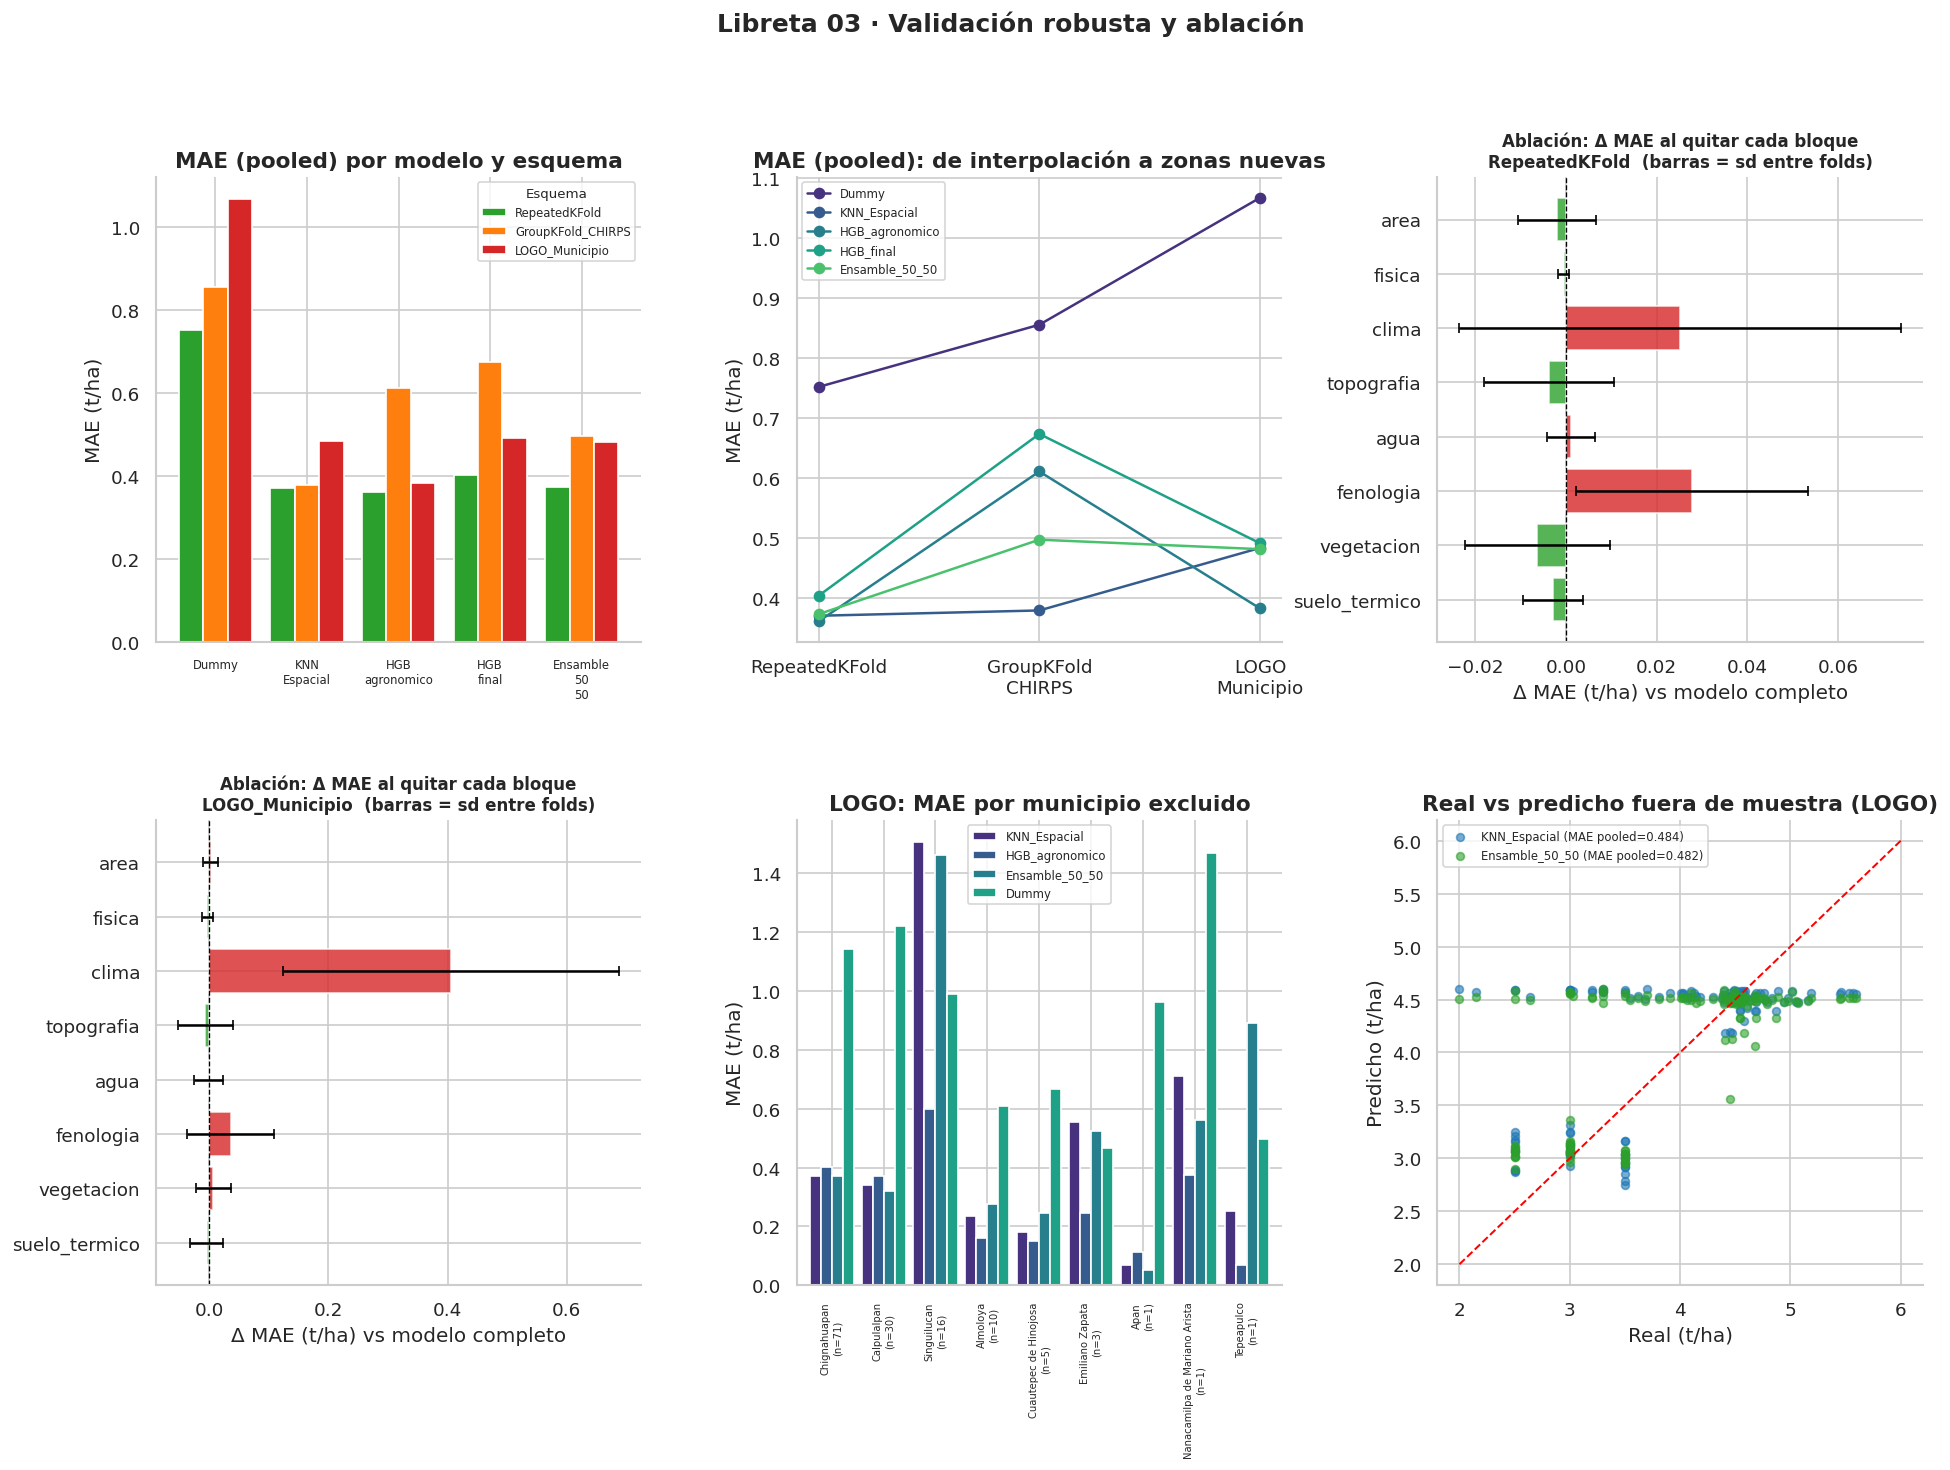

In [ ]:
# ============================================================
# 8. GRÁFICOS DE RESULTADOS
# ============================================================
fig = plt.figure(figsize=(19, 12))
gs = fig.add_gridspec(2, 3, hspace=0.38, wspace=0.32)
orden_modelos = ['Dummy', 'KNN_Espacial', 'HGB_agronomico', 'HGB_final', ENSAMBLE_NOMBRE]

# 1. MAE pooled por modelo y esquema
ax1 = fig.add_subplot(gs[0, 0])
piv = df_resultados.pivot(index='modelo', columns='esquema', values='MAE_pooled').loc[orden_modelos, ESQUEMAS]
piv.plot(kind='bar', ax=ax1, color=['#2ca02c', '#ff7f0e', '#d62728'], width=0.8)
ax1.set_title('MAE (pooled) por modelo y esquema'); ax1.set_ylabel('MAE (t/ha)'); ax1.set_xlabel('')
ax1.set_xticklabels([m.replace('_', '\n') for m in orden_modelos], rotation=0, fontsize=7)
ax1.legend(title='Esquema', fontsize=7, title_fontsize=8)

# 2. Del esquema optimista al estricto
ax2 = fig.add_subplot(gs[0, 1])
for m in orden_modelos:
    sub = df_resultados[df_resultados['modelo'] == m].set_index('esquema').loc[ESQUEMAS]
    ax2.plot(['RepeatedKFold', 'GroupKFold\nCHIRPS', 'LOGO\nMunicipio'], sub['MAE_pooled'].values, marker='o', label=m)
ax2.set_title('MAE (pooled): de interpolación a zonas nuevas'); ax2.set_ylabel('MAE (t/ha)'); ax2.legend(fontsize=7)

# 3 y 4. Ablación: Δ MAE al quitar cada bloque (con sd entre folds)
for pos, esquema in [((0, 2), 'RepeatedKFold'), ((1, 0), 'LOGO_Municipio')]:
    ax = fig.add_subplot(gs[pos])
    d = df_ablacion[(df_ablacion['esquema'] == esquema) & (df_ablacion['experimento'].str.startswith('Sin_'))].copy()
    d['bloque'] = d['experimento'].str.replace('Sin_', '')
    colores = ['#d62728' if v > 0 else '#2ca02c' for v in d['delta_vs_completo']]
    ax.barh(d['bloque'], d['delta_vs_completo'], xerr=d['delta_sd_folds'], color=colores, alpha=0.8, capsize=3)
    ax.axvline(0, color='black', linewidth=0.8, linestyle='--')
    ax.set_title(f'Ablación: Δ MAE al quitar cada bloque\n{esquema}  (barras = sd entre folds)', fontsize=10)
    ax.set_xlabel('Δ MAE (t/ha) vs modelo completo')

# 5. LOGO por municipio
ax5 = fig.add_subplot(gs[1, 1])
t = tabla_logo[['KNN_Espacial', 'HGB_agronomico', ENSAMBLE_NOMBRE, 'Dummy']]
t.plot(kind='bar', ax=ax5, width=0.85)
ax5.set_xticklabels([f"{i}\n(n={int(n)})" for i, n in zip(t.index, tabla_logo['n_parcelas'])], rotation=90, fontsize=6)
ax5.set_title('LOGO: MAE por municipio excluido'); ax5.set_ylabel('MAE (t/ha)'); ax5.set_xlabel('')
ax5.legend(fontsize=7)

# 6. Real vs predicho fuera de muestra (LOGO)
ax6 = fig.add_subplot(gs[1, 2])
for nombre, color in [('KNN_Espacial', '#1f77b4'), (ENSAMBLE_NOMBRE, '#2ca02c')]:
    p = predicciones_oof_todas[f'LOGO_Municipio__{nombre}']
    ax6.scatter(y, p, s=22, alpha=0.6, color=color, label=f'{nombre} (MAE pooled={mean_absolute_error(y, p):.3f})')
lim = [min(y.min(), 2), max(y.max(), 6)]
ax6.plot(lim, lim, 'r--', linewidth=1.2)
ax6.set_title('Real vs predicho fuera de muestra (LOGO)'); ax6.set_xlabel('Real (t/ha)'); ax6.set_ylabel('Predicho (t/ha)')
ax6.legend(fontsize=7)

fig.suptitle('Libreta 03 · Validación robusta y ablación', fontsize=15, fontweight='bold', y=0.995)
guardar_figura(fig, '04_validacion_robusta_ablacion.png', 'reports')
plt.show()

In [ ]:
# ============================================================
# 9. INTERPRETACIÓN (se genera a partir de los números; no hay conclusiones escritas de antemano)
# ============================================================
def metrica(esquema, modelo, col='MAE_fold_media'):
    f = df_resultados[(df_resultados['esquema'] == esquema) & (df_resultados['modelo'] == modelo)]
    return float(f[col].iloc[0])

print("=" * 72)
print("RESUMEN POR ESQUEMA (MAE medio por fold | MAE pooled)")
print("=" * 72)
for esquema in ESQUEMAS:
    partes = [f"{m}={metrica(esquema, m):.3f}|{metrica(esquema, m, 'MAE_pooled'):.3f}" for m in orden_modelos]
    print(f"{esquema:18s} " + "  ".join(partes))

veredicto = {'regla_decision': {'tolerancia_t_ha': TOLERANCIA_DECISION,
                                'diff_ensamble_vs_knn': float(fila['diff_media']),
                                'sd_folds': float(fila['diff_sd_folds']),
                                'cumple': cumple_regla}}

print("\n📌 Lectura (con cautela; ± = variabilidad entre folds, no intervalo de confianza):")
for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    p = df_pareadas[(df_pareadas['esquema'] == esquema) & (df_pareadas['a'] == 'HGB_agronomico') &
                    (df_pareadas['b'] == 'KNN_Espacial')].iloc[0]
    if abs(p['diff_media']) <= p['diff_sd_folds']:
        txt = "diferencia no detectable"
    elif p['diff_media'] > 0:
        txt = "el HGB agronómico tiene MAE mayor que el KNN espacial"
    else:
        txt = "el HGB agronómico tiene MAE menor que el KNN espacial"
    print(f"   {esquema}: HGB agronómico − KNN = {p['diff_media']:+.3f} ± {p['diff_sd_folds']:.3f} → {txt}")
    veredicto[f'hgb_agronomico_vs_knn_{esquema}'] = {'diff': float(p['diff_media']), 'sd': float(p['diff_sd_folds']), 'lectura': txt}

r2_max = float(df_residuos['R2_residuos'].max())
print(f"\n   Residuos del KNN explicados por variables satelitales: R² máximo = {r2_max:.3f} "
      + ("(no se detecta información adicional)" if r2_max <= 0 else "(hay indicios de información adicional; verificar con más repeticiones)"))
veredicto['r2_residuos_max'] = r2_max

# Ablación: solo se nombran bloques cuyo efecto supera la variabilidad entre folds
for esquema in ['RepeatedKFold', 'LOGO_Municipio']:
    d = df_ablacion[(df_ablacion['esquema'] == esquema) & (df_ablacion['experimento'].str.startswith('Sin_'))]
    relevantes = d[d['delta_vs_completo'].abs() > d['delta_sd_folds']]
    nombres = ", ".join(f"{r.experimento} ({r.delta_vs_completo:+.3f})" for r in relevantes.itertuples()) or "ninguno"
    print(f"   Ablación {esquema}: bloques con efecto mayor que su variabilidad entre folds → {nombres}")
    veredicto[f'ablacion_bloques_detectables_{esquema}'] = nombres

ruta_veredicto = CARPETAS['03_validacion'] / 'veredicto_validacion.json'
with open(ruta_veredicto, 'w', encoding='utf-8') as f:
    json.dump(veredicto, f, ensure_ascii=False, indent=2)
print(f"\n✅ Guardado: {ruta_veredicto}")

RESUMEN POR ESQUEMA (MAE medio por fold | MAE pooled)
RepeatedKFold      Dummy=0.752|0.752  KNN_Espacial=0.371|0.371  HGB_agronomico=0.361|0.361  HGB_final=0.404|0.404  Ensamble_50_50=0.373|0.373
GroupKFold_CHIRPS  Dummy=0.860|0.856  KNN_Espacial=0.375|0.379  HGB_agronomico=0.561|0.611  HGB_final=0.637|0.674  Ensamble_50_50=0.480|0.497
LOGO_Municipio     Dummy=0.891|1.067  KNN_Espacial=0.469|0.484  HGB_agronomico=0.276|0.383  HGB_final=0.597|0.491  Ensamble_50_50=0.523|0.482

📌 Lectura (con cautela; ± = variabilidad entre folds, no intervalo de confianza):
   RepeatedKFold: HGB agronómico − KNN = -0.010 ± 0.055 → diferencia no detectable
   LOGO_Municipio: HGB agronómico − KNN = -0.193 ± 0.303 → diferencia no detectable

   Residuos del KNN explicados por variables satelitales: R² máximo = -0.016 (no se detecta información adicional)
   Ablación RepeatedKFold: bloques con efecto mayor que su variabilidad entre folds → Sin_fenologia (+0.028)
   Ablación LOGO_Municipio: bloques con efect

In [ ]:
# ============================================================
# 10. EXPORTACIÓN DE ARTEFACTOS DE LA LIBRETA 03
# ============================================================
# Predicciones fuera de muestra (promedio de repeticiones) para análisis posteriores (Libreta 04)
df_oof = pd.DataFrame({'ID_POLIGONO': ids})
for clave, preds in predicciones_oof_todas.items():
    df_oof[clave] = preds
df_oof['RENDIMIENTO_T_HA'] = y.values
guardar_csv(df_oof, 'predicciones_oof_todos_esquemas.csv', '03_validacion')

df_meta_validacion = df_trabajo[['ID_POLIGONO', 'latitud', 'longitud', 'celda_chirps', 'grupo_municipio']].copy()
if 'estado' in df_trabajo.columns:
    df_meta_validacion['estado'] = df_trabajo['estado']
guardar_csv(df_meta_validacion, 'metadatos_espaciales_validacion.csv', '03_validacion')

resumen_libreta03 = {
    'version': '3.1-validacion-robusta-corregida',
    'n_parcelas_evaluadas': int(len(df_trabajo)),
    'esquemas_validacion': ESQUEMAS,
    'n_celdas_chirps': int(len(conteo_chirps)),
    'n_municipios': int(len(conteo_muni)),
    'modelos_evaluados': list(MODELOS) + [ENSAMBLE_NOMBRE],
    'bloques_ablacion': {k: len(v) for k, v in bloques.items()},
    'parametros': {'knn': PARAMS_KNN, 'hgb_agronomico': PARAMS_HGB, 'hgb_final': PARAMS_HGB_FINAL,
                   'k_vars': K_VARS, 'forzar_coordenadas': FORZAR_COORDS_HGB_FINAL,
                   'repeated_kfold': [N_SPLITS_RK, N_REPEATS_RK], 'semilla_cv': SEMILLA},
    'veredicto': veredicto,
    'alcance': 'retrospectivo; solo 138 parcelas etiquetadas; una sola temporada (2025)',
}
with open(CARPETAS['03_validacion'] / 'resumen_libreta03.json', 'w', encoding='utf-8') as f:
    json.dump(resumen_libreta03, f, ensure_ascii=False, indent=2)

print("=" * 70)
listar_archivos('03_validacion')
print("\n✅ LIBRETA 03 COMPLETADA")
print("\nArtefactos para el reporte:")
print("   1. resultados_validacion.csv / resultados_por_fold.csv → Tabla de modelos × esquemas")
print("   2. diferencias_pareadas.csv + logo_por_municipio.csv   → Regla de decisión y detalle LOGO")
print("   3. prueba_residuos.csv                                  → ¿Aportan los índices más allá de la ubicación?")
print("   4. resultados_ablacion.csv                              → Ablación por bloques")
print("   5. predicciones_oof_todos_esquemas.csv                  → Insumo de la Libreta 04")
print("   6. 04_validacion_robusta_ablacion.png                   → Sección Resultados y Discusión")
print("\n📌 Siguiente paso: Libreta 04 · Interpretabilidad y preguntas guía")

✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/predicciones_oof_todos_esquemas.csv
✅ Guardado: /content/drive/MyDrive/Reto_AgroCebada_2026/data/03_validacion/metadatos_espaciales_validacion.csv
📁 Carpeta '03_validacion': 10 archivos
   • diferencias_pareadas.csv (2.4 KB)
   • logo_por_municipio.csv (1.1 KB)
   • metadatos_espaciales_validacion.csv (11.4 KB)
   • predicciones_oof_todos_esquemas.csv (39.8 KB)
   • prueba_residuos.csv (330.0 B)
   • resultados_ablacion.csv (4.7 KB)
   • resultados_por_fold.csv (11.8 KB)
   • resultados_validacion.csv (2.6 KB)
   • resumen_libreta03.json (1.9 KB)
   • veredicto_validacion.json (665.0 B)

✅ LIBRETA 03 COMPLETADA

Artefactos para el reporte:
   1. resultados_validacion.csv / resultados_por_fold.csv → Tabla de modelos × esquemas
   2. diferencias_pareadas.csv + logo_por_municipio.csv   → Regla de decisión y detalle LOGO
   3. prueba_residuos.csv                                  → ¿Aportan los índices más allá de la

## 📋 Conclusiones de la Libreta 03

Esta libreta **no trae conclusiones escritas de antemano**: los números salen de las celdas anteriores (`resultados_validacion.csv`, `diferencias_pareadas.csv`, `prueba_residuos.csv`, `resultados_ablacion.csv`, `veredicto_validacion.json`) y el reporte debe citarlos desde ahí.

### Tres niveles de rigor en la validación
1. **RepeatedKFold** — parcelas vecinas pueden quedar en entrenamiento y validación. Mide la capacidad de *interpolar* entre parcelas intercaladas (el escenario de las 59 parcelas ocultas, si están intercaladas con las de entrenamiento).
2. **GroupKFold por celdas CHIRPS** — parcelas de una misma celda de ~5 km no se mezclan entre entrenamiento y validación.
3. **LOGO por municipio** — se excluye un municipio completo. Mide la generalización a zonas sin parcelas de referencia.

### Cómo redactar los resultados (lenguaje prudente)
- Usar "consistente con", "no se detectó" y "con los datos y variables evaluados"; evitar "demuestra", "comprobado" o "confirmado".
- Reportar siempre MAE, RMSE y R², junto con las líneas base y la variabilidad entre folds.
- En LOGO, citar **qué promedio** se usa (por municipio = `MAE_fold_media`, o sobre parcelas = `MAE_pooled`) y el **número de parcelas por municipio**.
- Las diferencias pareadas pequeñas frente a su variabilidad (|media| ≤ sd) se describen como "no detectables", no como "iguales".
- Una ablación sin diferencia detectable **no** significa que el bloque no importe: con 138 parcelas el poder estadístico es bajo y los bloques tienen tamaños distintos.

### Limitaciones que deben aparecer en el reporte
- Una sola temporada (2025) y 138 etiquetas.
- Ausencia de variedad, siembra, manejo y suelo.
- Hiperparámetros fijados con las mismas particiones (cifras ligeramente optimistas).
- Clima de ~5 km: parcelas vecinas comparten valores.

### Próximos pasos (Libreta 04)
- Importancia por variable repetida por fold (SHAP y permutación), agrupada por índice y por bloque.
- Verificar si las variables más importantes son proxies de ubicación (correlación con latitud, longitud y elevación).
- Responder con cifras las **preguntas guía** del reto y generar los artefactos para el dashboard.